In [12]:
from archetypes import AA

In [13]:
import pandas as pd
import numpy as np

In [14]:
all_data = pd.read_csv('/storage/homefs/mc21s017/data_vf/washington_data_td_all.csv')

In [15]:
all_values = all_data[[f'TD_{i}' for i in range(1,55)]].values # dropna()
all_values = (all_values - all_values.min(axis=0)) / (all_values.max(axis=0) - all_values.min(axis=0) + 1e-8)

In [19]:
aa = AA(n_archetypes=17, max_iter=1000, verbose=True)

In [20]:
all_values_ = np.delete(all_values, [25, 34], axis=1)
aa.fit(all_values_)

Iteration 10/1000: RSS = 13156.534711600281
Iteration 20/1000: RSS = 11803.5015121451
Iteration 30/1000: RSS = 10067.00006471161
Iteration 40/1000: RSS = 9324.694000122196
Iteration 50/1000: RSS = 8790.903389980202
Iteration 60/1000: RSS = 8201.914059318602
Iteration 70/1000: RSS = 7845.043798380066
Iteration 80/1000: RSS = 7590.441865850473
Iteration 90/1000: RSS = 7363.796658726875
Iteration 100/1000: RSS = 7263.269408933411
Iteration 110/1000: RSS = 7192.402468271495
Iteration 120/1000: RSS = 7134.141469517082
Iteration 130/1000: RSS = 7078.929041166499
Iteration 140/1000: RSS = 7032.060538725811
Iteration 150/1000: RSS = 6988.617621385725
Iteration 160/1000: RSS = 6953.024860816251
Iteration 170/1000: RSS = 6919.00672883715
Iteration 180/1000: RSS = 6881.431609089952
Iteration 190/1000: RSS = 6847.608488491271
Iteration 200/1000: RSS = 6815.120417769998
Iteration 210/1000: RSS = 6783.255815769604
Iteration 220/1000: RSS = 6753.930732168199
Iteration 230/1000: RSS = 6725.11728083522

,n_archetypes,17
,max_iter,1000
,verbose,True
,tol,0.0001
,init,'uniform'
,n_init,1
,init_params,None
,save_init,False
,method,'pgd'
,method_params,None
,random_state,None


In [21]:
B = aa.archetypes_

In [22]:
B.shape

(17, 52)

In [23]:
B_min = B.min(axis=0)
B_max = B.max(axis=0)
B_norm = (B - B_min) / (B_max - B_min + 1e-8)
B_norm = np.insert(B_norm, 25, -1000, axis=1)
B_norm = np.insert(B_norm, 34, -1000, axis=1)

In [26]:
K=17

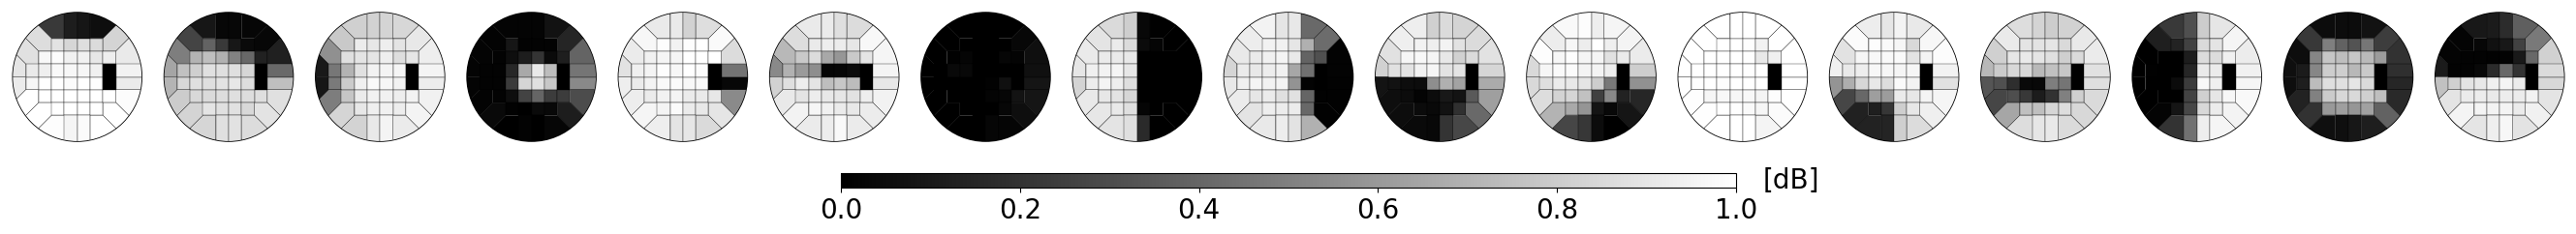

In [28]:
import matplotlib.pyplot as plt
from scipy.spatial import Voronoi
from matplotlib.patches import Circle, Polygon
from matplotlib.collections import PatchCollection

def voronoi_finite_polygons_2d(vor, radius=None):
    if vor.points.shape[1] != 2:
        raise ValueError("Requires 2D input")

    new_regions = []
    new_vertices = vor.vertices.tolist()

    center = vor.points.mean(axis=0)
    if radius is None:
        radius = vor.points.ptp().max() * 2

    all_ridges = {}
    for (p1, p2), (v1, v2) in zip(vor.ridge_points, vor.ridge_vertices):
        all_ridges.setdefault(p1, []).append((p2, v1, v2))
        all_ridges.setdefault(p2, []).append((p1, v1, v2))

    for p1, region_idx in enumerate(vor.point_region):
        vertices = vor.regions[region_idx]

        if all(v >= 0 for v in vertices):
            new_regions.append(vertices)
            continue

        ridges = all_ridges[p1]
        new_region = [v for v in vertices if v >= 0]

        for p2, v1, v2 in ridges:
            if v2 < 0:
                v1, v2 = v2, v1
            if v1 >= 0:
                continue

            t = vor.points[p2] - vor.points[p1]
            t /= np.linalg.norm(t)
            nvec = np.array([-t[1], t[0]])

            midpoint = vor.points[[p1, p2]].mean(axis=0)
            direction = np.sign(np.dot(midpoint - center, nvec)) * nvec
            far_point = vor.vertices[v2] + direction * radius

            new_region.append(len(new_vertices))
            new_vertices.append(far_point.tolist())

        vs = np.asarray([new_vertices[v] for v in new_region])
        c = vs.mean(axis=0)
        angles = np.arctan2(vs[:, 1] - c[1], vs[:, 0] - c[0])
        new_region = [v for _, v in sorted(zip(angles, new_region))]
        new_regions.append(new_region)

    return new_regions, np.asarray(new_vertices)

# coords = pd.read_excel(
#     "/Users/martacolmenar/Documents/PeriVision/Prediction-dissease-stage/Insel/x_y.xlsx"
#  )[["V1", "V2"]].values

coords = pd.read_csv('/storage/homefs/mc21s017/data_vf/p24d2.csv').values

# Voronoi tessellation
vor = Voronoi(coords)
regions, vertices = voronoi_finite_polygons_2d(vor, radius=200)

# Plot setup
fig, axes = plt.subplots(1, K, figsize=(30, 15))
fig.subplots_adjust(left=0.02, right=0.90, top=0.88, bottom=0.08, wspace=0.12)
norm = plt.Normalize(vmin=0, vmax=1)
cmap = plt.cm.grey

VFs_archetypes = B_norm
radius_deg = 30

for idx, VF in enumerate(VFs_archetypes):
    ax = axes.flat[idx]

    # Circular visual field boundary (30 deg)
    boundary = Circle((0, 0), radius_deg, fill=False, edgecolor="black", linewidth=1.2)
    ax.add_patch(boundary)

    patches = []
    colors = []
    for i, region in enumerate(regions):
        polygon = vertices[region]
        poly_patch = Polygon(polygon, closed=True)
        patches.append(poly_patch)
        colors.append(VF[i])

    coll = PatchCollection(
        patches,
        cmap=cmap,
        norm=norm,
        edgecolor="black",
        linewidth=0.25,
    )
    coll.set_array(np.asarray(colors))
    coll.set_clip_path(boundary)
    ax.add_collection(coll)

    ax.set_aspect("equal")
    ax.set_xlim(-radius_deg - 1.5, radius_deg + 1.5)
    ax.set_ylim(-radius_deg - 1.5, radius_deg + 1.5)
    ax.axis("off")

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
# Bottom-middle horizontal colorbar
left = axes[0].get_position().x0
right = axes[-1].get_position().x1
bottom = axes[0].get_position().y0

cbar_width = (right - left) * 0.35
cbar_height = 0.01
cbar_x = left + ((right - left) - cbar_width) / 2
cbar_y = bottom - 0.03

cax = fig.add_axes([cbar_x, cbar_y, cbar_width, cbar_height])
cbar = fig.colorbar(sm, cax=cax, orientation="horizontal")
cbar.ax.text(
    1.03, 0.5, "[dB]",
    transform=cbar.ax.transAxes,
    va="center", ha="left", fontsize=20
)
cbar.ax.tick_params(labelsize=20)
plt.savefig('/storage/homefs/mc21s017/archetypes-242.png')
plt.show()
